In [1]:
#breast Cancer Dataset اهلا بيكم انا تيم علي و النهارده هشرح النوت بوك عن ال
#(Benign) أو خبيثة (Malignant)او بمعني مجموعة من البيانات الطبية  لتصنيف الأورام إلى حميدة

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, r2_score
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
import matplotlib.pyplot as plt
import seaborn as sns
#هنا تستدعي الأدوات اللي هتبني بيها

In [3]:
df = pd.read_csv("breast-cancer.csv")
#هنا بقرا الملف

In [4]:
df
#"هنا بيعرضلي جدول البيانات لمعاينته

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [5]:
df.head()
#هنا بيعرضلي أول 5 صفوف فقط من جدول البيانات

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [6]:
df.tail()
#هنا بيعرضلي آخر 5 صفوف فقط من جدول البيانات

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400
568,92751,B,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,...,9.456,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039


In [7]:
df.info()
#هنا بيعرضلي التقرير الفني والمعلومات الأساسية عن هيكل الجدول

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [8]:
df.describe()
#هنا بيعرضلي التقرير الإحصائي الكامل للأرقام الموجودة في الجدول

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [9]:
df.isnull().sum()
#احسب لي عدد القيم المفقودة (الفارغة) في كل عمود من أعمدة الجدول"

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


In [10]:
df.duplicated().sum()
#هنا بسال نفسي سوال هل هناك أي صفوف مكررة بالكامل في هذا الجدول؟ وإذا وُجدت، احسب لي عدده

np.int64(0)

In [11]:
df.nunique()
 #هنا بيحسبلي عدد القيم الفريدة والمميزة (بدون تكرار) في كل عمود من أعمدة الجدول

,0
id,569
diagnosis,2
radius_mean,456
texture_mean,479
perimeter_mean,522
area_mean,539
smoothness_mean,474
compactness_mean,537
concavity_mean,537
concave points_mean,542


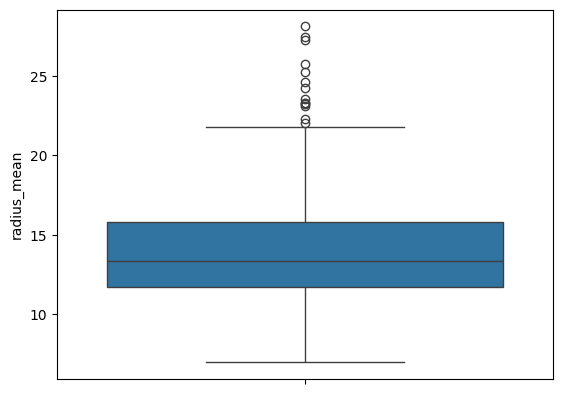

In [12]:
sns.boxplot(data=df, y="radius_mean")
plt.show()
#Boxplot هنا بيرسم
#لعمود أحجام الأورام صندوق يوضح توزيع الأرقام والنسب الإحصائية

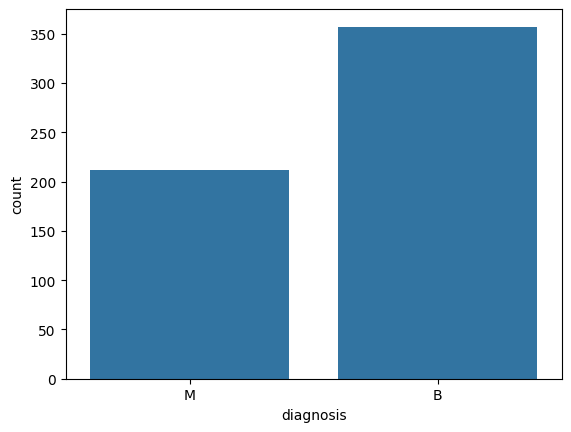

In [13]:
sns.countplot(data=df, x="diagnosis")
plt.show()
#Countplot هنا رسملي
# يعدّ ويحسب كم حالة مصابة بورم خبيث وكم حالة بورم حميد في الجدول

<Axes: xlabel='diagnosis', ylabel='radius_mean'>

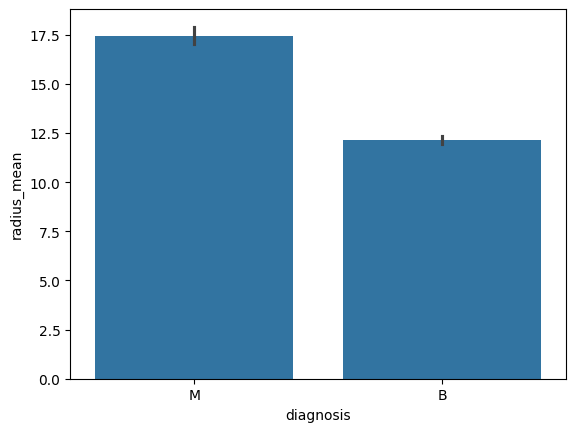

In [14]:
sns.barplot(data=df, x="diagnosis", y="radius_mean")

#Barplotهنا رسملي
# يوضح متوسط حجم الورم  لكل نوع من أنواع التشخيص (خبيث وحميد) لمقارنة الفرق بينهما".

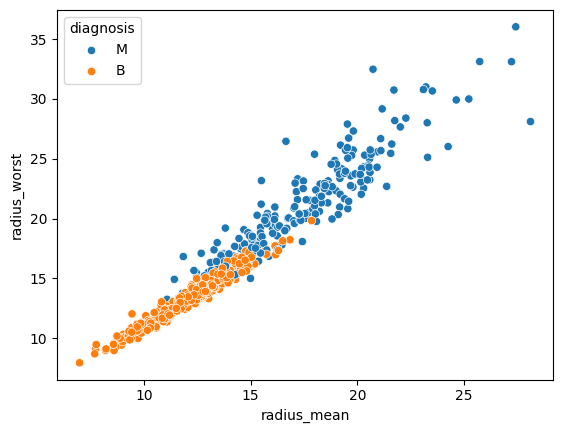

In [15]:
sns.scatterplot(data=df, x="radius_mean", y="radius_worst", hue="diagnosis")
plt.show()
#Scatter Plot ده بيعمل
#radius_mean و radius_worst عشان يوضح العلاقة بين

In [16]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
#ده بيستورد الأدوات اللي هنحتاجها لتحميل البيانات وتقسيمها وتقييم الموديل

In [17]:
cancer = load_breast_cancer()
df = pd.DataFrame(
    cancer.data,
    columns=cancer.feature_names
)

#DataFrame هنا الكود ده بيحمّل بيانات سرطان الثدي وبيحوّلها إلى جدول

In [18]:
df['Type'] = cancer.target
#بنضيف عمود التشخيص لكل حالة عشان نستخدمه في تدريب الموديل

In [19]:
x = df.drop("Type", axis=1)
y = df["Type"]
# دي البيانات الي الموديل بيتعلم منها x
# هي الإجابة اللي الموديل هيتعلم يتوقعها y و

In [20]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3,
    random_state=0
)
# نقسم البيانات إلى %70 تدريب
#و30% اختبار عشان ندرّب الموديل ونختبر قدرته على التوقع

In [21]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)
dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)
print("DT Accuracy: ", accuracy_score(y_test, y_pred_dt))
# ندرّبها، نخليها تتوقع نوع الورمDecision Tree بنبني
#دقتهاوبعدها نحسب نسبه دقتها

DT Accuracy:  0.9415204678362573


In [22]:
from sklearn.ensemble import RandomForestClassifier

RF_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)
RF_model.fit(x_train, y_train)
y_pred_rf = RF_model.predict(x_test)
print("RF Accuracy: ", accuracy_score(y_test, y_pred_rf))
#Random Forest بيعمل موديل
#لتصنيف سرطان الثدي، وبعدها بيحسب دقته

RF Accuracy:  0.9649122807017544


In [23]:
from sklearn.svm import SVC

svm_model = SVC(kernel="rbf", C=100)
svm_model.fit(x_train, y_train)
svm_pred = svm_model.predict(x_test)
print("SVM Accuracy: ", accuracy_score(y_test, svm_pred))
#Support Vector Machine كود ده بيستخدم
#لتصنيف سرطان الثدي وحساب دقة الموديل


SVM Accuracy:  0.9532163742690059


In [24]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
#K-Means Clustering ده بيستورد أداتين لاستخدامهم في

In [25]:
x_cluster = df[['mean radius', 'mean texture']]
#K-Means بنختار خاصيتين من بيانات سرطان الثدي عشان نقسّم الحالات إلى مجموعات متشابهة باستخدام

In [26]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x_cluster)
# K-Meansللبيانات قبل استخدامStandardization الكود ده بيعمل

In [27]:
model = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_pred = model.fit_predict(x_scaled)

print("Cluster Predictions:\n", clusters_pred)
#لتقسيم بيانات سرطان الثدي إلى مجموعتين k-mean ده بيستخدم

Cluster Predictions:
 [1 0 0 1 0 1 0 1 1 0 0 1 0 0 0 0 1 0 0 1 1 1 1 0 0 1 0 0 0 1 0 1 0 0 1 0 0
 1 0 1 1 1 0 1 1 0 1 1 1 0 1 1 1 0 0 1 0 0 1 1 1 1 0 1 0 0 1 1 1 1 0 1 0 1
 1 0 1 0 0 1 1 1 0 0 1 0 0 0 1 1 0 0 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1
 1 1 1 1 1 1 1 0 0 1 0 0 1 1 1 0 0 1 0 1 0 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 0 1 1 1 1 1 1 1 1 0 1 1 0 0 0 1 0
 1 0 1 1 1 0 1 1 0 0 1 0 0 0 1 1 0 0 0 1 1 1 0 0 1 0 1 0 0 0 1 1 1 0 0 1 1
 1 0 1 1 1 1 0 1 0 0 0 0 1 0 0 0 0 0 1 1 1 0 0 1 1 1 1 1 0 1 0 0 0 1 0 1 0
 0 0 0 0 0 0 0 1 0 1 1 1 1 0 1 0 1 1 0 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 0 1 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 1 1 1 1 0 0 1 1 1
 1 1 0 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 0 0 0 1 1 1 1 1 1 1 1 1 0 1 0 0 1 0 0
 0 1 0 0 1 1 1 0 1 1 1 1 1 1 1 0 1 1 1 0 1 1 0 0 1 1 1 1 1 1 0 1 1 1 1 1 1
 1 0 1 1 1 1 0 0 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 0 1 1 1 1 1 1 1 0 1 1
 0 0 0 1 1 0 1 0 0 1 1 0 0 0 0 0 0 0 0 1 1 1 1 1 0 1 1 0 1 0 1 1 1 1 1 0 1
 1 

In [28]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, r2_score
import pandas as pd
#ده بيستورد الأدوات اللي هنحتاجها لتجهيز البيانات وتدريب الموديل وتقييمه

In [29]:
df = pd.read_csv("breast-cancer.csv")
if 'id' in df.columns:
    df = df.drop(columns=['id'])
    #ده بيقرأ ملف البيانات
    # لو موجودid وبيحذف عمود


In [30]:
le = LabelEncoder()
df['Type'] = le.fit_transform(df['diagnosis'])
df = df.drop(columns=['diagnosis'])

x = df.drop(columns=['Type'])
y = df['Type']
#Feature (x) , Target (y) الكود ده بيحوّل التشخيص لأرقام، وبعدها بيقسم البيانات إلي

In [31]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=0
)
#الكود ده بيقسّم البيانات إلى بيانات تدريب وبيانات اختبار

In [32]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)
#للبيانات قبل تدريب الموديل Standardization الكود ده بيعمل

In [33]:
x_reg = df.drop(columns=['Type', 'radius_worst'])
y_reg = df['radius_worst']
xr_train, xr_test, yr_train, yr_test = train_test_split(x_reg, y_reg, test_size=0.3, random_state=0)
#Linear Regression ده بيجهّز البيانات لاستخدام
#radius_worst لتنبؤ بقيمة

In [34]:
x_reg = df.drop(columns=['Type', 'radius_worst'])
y_reg = df['radius_worst']
xr_train, xr_test, yr_train, yr_test = train_test_split(x_reg, y_reg, test_size=0.3, random_state=0)
#Linear Regression ده بيجهّز البيانات لاستخدام

In [35]:
lin_reg = LinearRegression()
lin_reg.fit(xr_train, yr_train)
y_pred_lin = lin_reg.predict(xr_test)
print("Linear Regression R² Score: ", r2_score(yr_test, y_pred_lin))
#Linear Regression ده بيجهّز البيانات لاستخدام
#radius_worst لتنبؤ بقيمة
#وبعدها بيقيّم أداء الموديل

Linear Regression R² Score:  0.9981739134689401


In [36]:
log_reg = LogisticRegression(random_state=42, max_iter=10000)
log_reg.fit(x_train_scaled, y_train)
y_pred_log = log_reg.predict(x_test_scaled)
print("Logistic Regression Accuracy: ", accuracy_score(y_test, y_pred_log))
#Logistic Regression ده بيستخدم
# الموديل بيتعلم يميّز بين الورم الحميد والخبيث، وبعدها بنحسب نسبة دقته

Logistic Regression Accuracy:  0.9766081871345029


In [37]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train_scaled, y_train)
y_pred_knn = knn_model.predict(x_test_scaled)
print("KNN Accuracy: ", accuracy_score(y_test, y_pred_knn))
#KNN الكود ده بيستخدم
#الموديل بيحدد إذا كان الورم حميد أو خبيث بناءً على أقرب 5 حالات مشابهة له في البيانات، وبعدها بنحسب دقته

KNN Accuracy:  0.9590643274853801


In [38]:
dt_model = DecisionTreeClassifier(max_depth=3, random_state=42)
dt_model.fit(x_train, y_train)
y_pred_dt = dt_model.predict(x_test)
print("Decision Tree Accuracy: ", accuracy_score(y_test, y_pred_dt))
#Decision Tree ده بيستخدم
#الموديل بيستخدم شجرة قرارات عشان يحدد إذا كان الورم حميد أو خبيث، وبعدها بنحسب دقته

Decision Tree Accuracy:  0.9415204678362573


In [39]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)
y_pred_rf = rf_model.predict(x_test)
print("Random Forest Accuracy: ", accuracy_score(y_test, y_pred_rf))
#Random Forest ده بيستخدم
#الموديل بيجمع نتائج 100 شجرة قرار عشان يتوقع إذا كان الورم حميد أو خبيث، وبعدها بنحسب دقته

Random Forest Accuracy:  0.9649122807017544


In [40]:
svm_model = SVC(kernel="rbf", C=100)
svm_model.fit(x_train_scaled, y_train)
svm_pred = svm_model.predict(x_test_scaled)
print("SVM Accuracy: ", accuracy_score(y_test, svm_pred))
#SVM (Support Vector Machine) لكود ده بيستخدم
# SVM الموديل بيتعلم يميّز بين الورم الحميد والخبيث باستخدام
#بعدها بنحسب دقته

SVM Accuracy:  0.9707602339181286


In [41]:
nb_model = GaussianNB()
nb_model.fit(x_train_scaled, y_train)
y_pred_nb = nb_model.predict(x_test_scaled)
print("Naive Bayes Accuracy: ", accuracy_score(y_test, y_pred_nb))
#Naive Bayes الكود ده بيستخدم
#الموديل بيستخدم الاحتمالات عشان يتوقع إذا كان الورم حميد أو خبيث، وبعدها بنحسب دقته

Naive Bayes Accuracy:  0.9122807017543859


In [42]:
kmeans_model = KMeans(n_clusters=2, random_state=42, n_init=10)
clusters_pred = kmeans_model.fit_predict(x_train_scaled)
print("K-Means Cluster Predictions Sample:", clusters_pred[:10])
#0,1 الموديل بيقسّم الحالات إلى مجموعتين، وكل حالة بتاخد رقم
#من غير ما يستخدم التشخيص الحقيقي أثناء التجميع
#Unsupervised Learning يعني دي
#مش تصنيف مباشر للورم

K-Means Cluster Predictions Sample: [1 1 1 1 1 1 1 1 1 0]


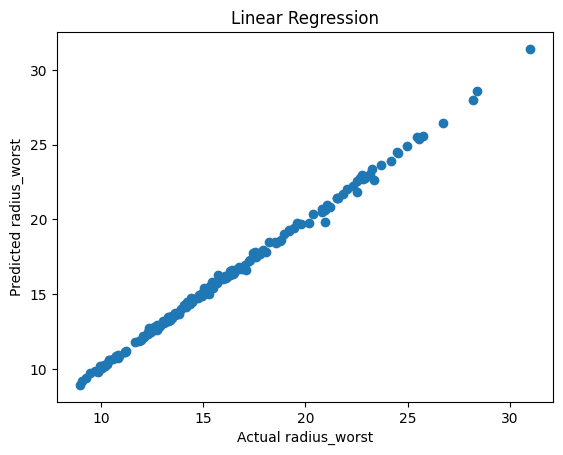

In [43]:
plt.scatter(yr_test, y_pred_lin)
plt.xlabel("Actual radius_worst")
plt.ylabel("Predicted radius_worst")
plt.title("Linear Regression")
plt.show()
#نقارن دقة الموديلات الستة مع بعض عشان نعرف مين حقق أفضل نتيجة على بيانات الاختبار.

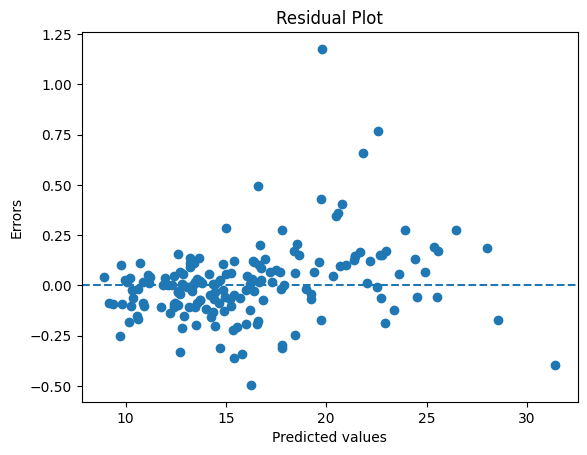

In [44]:
plt.scatter(y_pred_lin, yr_test - y_pred_lin)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted values")
plt.ylabel("Errors")
plt.title("Residual Plot")
plt.show()
#هو الفرق بين القيمة الحقيقية والقيمة المتوقعةـ Residual

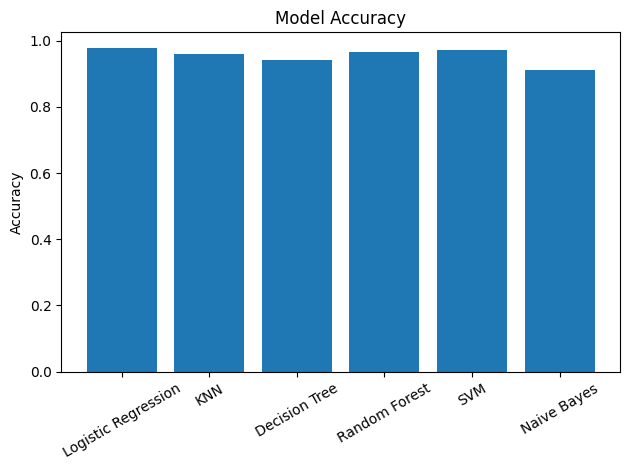

In [45]:
names = ["Logistic Regression", "KNN", "Decision Tree",
         "Random Forest", "SVM", "Naive Bayes"]
predictions = [y_pred_log, y_pred_knn, y_pred_dt,
               y_pred_rf, svm_pred, y_pred_nb]

scores = []
for pred in predictions:
    scores.append(accuracy_score(y_test, pred))

plt.bar(names, scores)
plt.ylabel("Accuracy")
plt.title("Model Accuracy")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()
#بنقارن دقة الموديلات الستة مع بعض عشان نعرف مين حقق أفضل نتيجة على بيانات الاختبار

<function matplotlib.pyplot.show(close=None, block=None)>

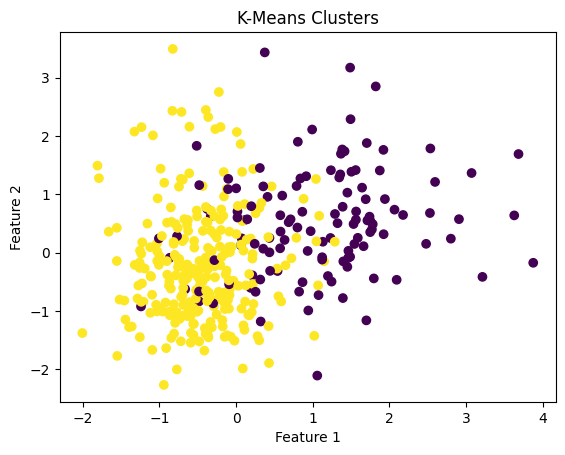

In [48]:
plt.scatter(x_train_scaled[:, 0], x_train_scaled[:, 1], c=clusters_pred)
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("K-Means Clusters")
plt.show
#بنعرض النقاط على رسم ثنائي الأبعاد عشان نشوف المجموعات اللي K-Means قسم الداتا ليها.